# Brain Language Model — Training and Evaluation

**Goal:** train a small autoregressive transformer (the actual "language
model" in BLM) on each of the 3 shortlisted RVQ tokenizers, and compare them
on held-out perplexity — the plan agreed on: filter tokenizers cheaply first
(done in `rvq_sweep.ipynb`), then only spend BLM training budget on the
survivors.

**Inputs:**
- `/content/drive/MyDrive/ds003844_processed/rvq_sweep/shortlist_for_blm.pkl`
  (from `rvq_sweep.ipynb` — contains the 3 shortlisted configs' token
  sequences and checkpoints)

**What this notebook does:**
1. Load the shortlist, rebuild per-recording token sequences for each config
2. Split by recording into train/val (same convention as the RVQ sweep)
3. Define a small causal (autoregressive) transformer over the token vocabulary
4. Train one BLM per shortlisted tokenizer config, next-token cross-entropy loss
5. Evaluate: held-out perplexity (the headline metric), training curves,
   per-config comparison, and prediction-quality diagnostics (confusion
   pattern, calibration)
6. All plots saved and displayed inline


## 0. Setup

In [ ]:
!pip -q install scikit-learn --upgrade
from google.colab import drive
drive.mount('/content/drive')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 57.6 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
import os
import pickle
import math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PROCESSED_DIR = "/content/drive/MyDrive/ds003844_processed"
SHORTLIST_PATH = os.path.join(PROCESSED_DIR, "rvq_sweep", "shortlist_for_blm.pkl")
BLM_DIR = os.path.join(PROCESSED_DIR, "blm")
PLOTS_DIR = os.path.join(BLM_DIR, "plots")
os.makedirs(BLM_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

print("Shortlist path exists:", os.path.exists(SHORTLIST_PATH))


Device: cuda
Shortlist path exists: True


## 1. Load shortlist, rebuild sequences, split by recording

Same recording-level, subject-stratified train/val split logic used in the
RVQ sweep — consistent across the whole pipeline, and necessary here for the
same reason: splitting by window would leak context between train and val.


In [ ]:
with open(SHORTLIST_PATH, "rb") as f:
    shortlist_data = pickle.load(f)

shortlist_names = shortlist_data["shortlist_names"]
shortlist = shortlist_data["shortlist"]
recording_names = shortlist_data["recording_names"]
sequence_lengths = shortlist_data["sequence_lengths"]

print("Shortlisted configs:", shortlist_names)
print("Recordings:", len(recording_names))
print("Total windows:", sum(sequence_lengths))


Shortlisted configs: ['cb16_L1', 'cb32_L1', 'cb64_L1']
Recordings: 33
Total windows: 3684


In [ ]:
import re
SUB_RE = re.compile(r"(sub-[A-Za-z0-9]+)")

def parse_subject(name):
    m = SUB_RE.search(name)
    return m.group(1) if m else "unknown_subject"

subjects_per_rec = [parse_subject(n) for n in recording_names]
print("Unique subjects:", sorted(set(subjects_per_rec)))


Unique subjects: ['sub-RESP0059', 'sub-RESP0280', 'sub-RESP0356', 'sub-RESP0384', 'sub-RESP0465']


In [ ]:
rng = np.random.RandomState(42)
subject_to_recs = defaultdict(list)
for i, subj in enumerate(subjects_per_rec):
    subject_to_recs[subj].append(i)

train_rec_idx, val_rec_idx = [], []
VAL_FRACTION = 0.2
for subj, rec_indices in subject_to_recs.items():
    rec_indices = rec_indices.copy()
    rng.shuffle(rec_indices)
    n_val = max(1, int(round(len(rec_indices) * VAL_FRACTION))) if len(rec_indices) > 1 else 0
    val_rec_idx += rec_indices[:n_val]
    train_rec_idx += rec_indices[n_val:]

train_rec_idx = sorted(train_rec_idx)
val_rec_idx = sorted(val_rec_idx)
print(f"Train recordings: {len(train_rec_idx)} | Val recordings: {len(val_rec_idx)}")

def rebuild_sequences(flat_labels, seq_lengths):
    """Flat per-window token array -> list of per-recording token sequences."""
    sequences = []
    idx = 0
    for length in seq_lengths:
        sequences.append(flat_labels[idx:idx + length])
        idx += length
    return sequences


Train recordings: 26 | Val recordings: 7


## 2. BLM model — small causal transformer over the token vocabulary

Matches the style of Notebook 3's transformer (`d_model=128`, `nhead=8`,
sinusoidal positional encoding) but adapted for what a *language model*
actually needs, as distinct from Notebook 3's masked-reconstruction encoder:

- **Token embedding**, not continuous input — the whole point of tokenizing
  was to get a discrete vocabulary; this is the first place that vocabulary
  gets used as such.
- **Causal masking** — each position can only attend to earlier positions,
  so the model is genuinely predicting the *next* token from *past* context,
  not peeking at the future. This is what makes it an autoregressive
  language model rather than a masked autoencoder like Notebook 3.
- **Cross-entropy loss over the vocabulary**, not MSE over floats — the
  actual language-modeling objective, and what makes perplexity a
  meaningful metric to report.


In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=2000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class BrainLM(nn.Module):
    def __init__(self, vocab_size, d_model=128, nhead=8, num_layers=2, max_len=2000, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(d_model, max_len)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=4 * d_model,
            dropout=dropout, batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_head = nn.Linear(d_model, vocab_size)

    def forward(self, tokens, padding_mask=None):
        # tokens: (batch, seq_len)
        seq_len = tokens.size(1)
        # bool causal mask (True = block attention), matching padding_mask's
        # bool dtype avoids a PyTorch deprecation warning about mismatched
        # mask/src_key_padding_mask dtypes.
        causal_mask = torch.triu(
            torch.ones(seq_len, seq_len, dtype=torch.bool, device=tokens.device), diagonal=1
        )
        x = self.token_embedding(tokens) * math.sqrt(self.d_model)
        x = self.pos_encoding(x)
        x = self.transformer(x, mask=causal_mask, src_key_padding_mask=padding_mask)
        return self.output_head(x)


## 3. Vocabulary remapping and batching

RVQ token IDs are sparse within their combinatorial range (e.g. cb64_L1 only
actually uses up to 64 distinct values out of however many raw IDs appear) —
remapped to a dense `0..vocab_size-1` range so the embedding table isn't
wastefully sized. Sequences are padded per-batch and a padding mask stops the
model from attending to or being scored on padding positions.


In [ ]:
def remap_vocab(sequences):
    """Map raw token IDs to a dense 0..V-1 range. Returns remapped sequences
    and the vocab size."""
    all_ids = sorted(set(int(t) for seq in sequences for t in seq))
    id_to_dense = {tok: i for i, tok in enumerate(all_ids)}
    remapped = [np.array([id_to_dense[int(t)] for t in seq]) for seq in sequences]
    return remapped, len(all_ids), id_to_dense


def make_batches(sequences, batch_size, pad_value):
    """Pads sequences per-batch (not globally) to reduce wasted compute on
    padding when sequence lengths vary a lot."""
    order = sorted(range(len(sequences)), key=lambda i: len(sequences[i]))
    batches = []
    for start in range(0, len(order), batch_size):
        idx_group = order[start:start + batch_size]
        max_len = max(len(sequences[i]) for i in idx_group)
        batch_tokens = np.full((len(idx_group), max_len), pad_value, dtype=np.int64)
        batch_mask = np.ones((len(idx_group), max_len), dtype=bool)  # True = pad
        for row, i in enumerate(idx_group):
            L = len(sequences[i])
            batch_tokens[row, :L] = sequences[i]
            batch_mask[row, :L] = False
        batches.append((batch_tokens, batch_mask))
    return batches


## 4. Train one BLM per shortlisted config

Next-token prediction: input is tokens `[0..T-2]`, target is tokens
`[1..T-1]` — standard autoregressive setup. Padding positions are excluded
from the loss via `ignore_index`. Small model given the mini dataset size —
`d_model=128` matches your pipeline's convention throughout, kept modest on
layers/heads to avoid overfitting the small token sequences further than the
RVQ stage already risked.


In [ ]:
D_MODEL = 128
NHEAD = 8
NUM_LAYERS = 2
BATCH_SIZE = 8       # sequences per batch (not windows — sequences are long)
EPOCHS = 200
LR = 3e-4

def train_blm(sequences_train, sequences_val, vocab_size, config_name):
    ckpt_path = os.path.join(BLM_DIR, f"blm_{config_name}.pt")
    pad_value = vocab_size  # reserve one extra ID for padding
    model = BrainLM(
        vocab_size=vocab_size + 1, d_model=D_MODEL, nhead=NHEAD,
        num_layers=NUM_LAYERS, max_len=max(len(s) for s in sequences_train + sequences_val) + 1,
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=15)

    train_batches = make_batches(sequences_train, BATCH_SIZE, pad_value)
    val_batches = make_batches(sequences_val, BATCH_SIZE, pad_value)

    history = {"train_loss": [], "val_loss": [], "val_ppl": []}
    best_val_loss = float("inf")
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_loss, epoch_tokens = 0.0, 0
        for batch_tokens, batch_mask in train_batches:
            batch_tokens_t = torch.tensor(batch_tokens, device=device)
            batch_mask_t = torch.tensor(batch_mask, device=device)

            inputs = batch_tokens_t[:, :-1]
            targets = batch_tokens_t[:, 1:]
            input_mask = batch_mask_t[:, :-1]

            logits = model(inputs, padding_mask=input_mask)
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)), targets.reshape(-1),
                ignore_index=pad_value, reduction="sum",
            )
            n_real_tokens = (targets != pad_value).sum().item()
            if n_real_tokens == 0:
                continue

            optimizer.zero_grad()
            (loss / n_real_tokens).backward()
            optimizer.step()

            epoch_loss += loss.item()
            epoch_tokens += n_real_tokens

        train_loss = epoch_loss / max(epoch_tokens, 1)
        history["train_loss"].append(train_loss)

        model.eval()
        val_loss_sum, val_tokens = 0.0, 0
        with torch.no_grad():
            for batch_tokens, batch_mask in val_batches:
                batch_tokens_t = torch.tensor(batch_tokens, device=device)
                batch_mask_t = torch.tensor(batch_mask, device=device)
                inputs = batch_tokens_t[:, :-1]
                targets = batch_tokens_t[:, 1:]
                input_mask = batch_mask_t[:, :-1]
                logits = model(inputs, padding_mask=input_mask)
                loss = F.cross_entropy(
                    logits.reshape(-1, logits.size(-1)), targets.reshape(-1),
                    ignore_index=pad_value, reduction="sum",
                )
                n_real_tokens = (targets != pad_value).sum().item()
                val_loss_sum += loss.item()
                val_tokens += n_real_tokens

        val_loss = val_loss_sum / max(val_tokens, 1)
        val_ppl = math.exp(min(val_loss, 20))  # cap to avoid overflow on early bad epochs
        history["val_loss"].append(val_loss)
        history["val_ppl"].append(val_ppl)
        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone().cpu() for k, v in model.state_dict().items()}

        if epoch % 20 == 0 or epoch == 1:
            print(f"  [{config_name}] epoch {epoch:4d}/{EPOCHS} | "
                  f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_ppl={val_ppl:.3f}")

    model.load_state_dict(best_state)
    result = {
        "config_name": config_name,
        "vocab_size": vocab_size,
        "pad_value": pad_value,
        "state_dict": best_state,
        "history": history,
        "best_val_loss": best_val_loss,
        "best_val_ppl": math.exp(min(best_val_loss, 20)),
    }
    torch.save(result, ckpt_path)
    return result, model


In [ ]:
blm_results = {}
blm_models = {}

for name in shortlist_names:
    print(f"=== Training BLM for tokenizer config: {name} ===")
    cfg_data = shortlist[name]
    flat_labels = cfg_data["token_labels_flat"]
    sequences = rebuild_sequences(flat_labels, sequence_lengths)
    sequences_remapped, vocab_size, id_map = remap_vocab(sequences)

    seq_train = [sequences_remapped[i] for i in train_rec_idx]
    seq_val = [sequences_remapped[i] for i in val_rec_idx]

    print(f"  vocab_size={vocab_size} | train sequences={len(seq_train)} | val sequences={len(seq_val)}")

    result, model = train_blm(seq_train, seq_val, vocab_size, name)
    blm_results[name] = result
    blm_models[name] = model
    print(f"  best val_loss={result['best_val_loss']:.4f} | best val perplexity={result['best_val_ppl']:.3f}\n")


=== Training BLM for tokenizer config: cb16_L1 ===
  vocab_size=16 | train sequences=26 | val sequences=7
  [cb16_L1] epoch    1/200 | train_loss=2.6011 | val_loss=2.1608 | val_ppl=8.678
  [cb16_L1] epoch   20/200 | train_loss=0.3226 | val_loss=0.3134 | val_ppl=1.368
  [cb16_L1] epoch   40/200 | train_loss=0.2600 | val_loss=0.2594 | val_ppl=1.296
  [cb16_L1] epoch   60/200 | train_loss=0.2197 | val_loss=0.2105 | val_ppl=1.234
  [cb16_L1] epoch   80/200 | train_loss=0.1995 | val_loss=0.1942 | val_ppl=1.214
  [cb16_L1] epoch  100/200 | train_loss=0.1767 | val_loss=0.1997 | val_ppl=1.221
  [cb16_L1] epoch  120/200 | train_loss=0.1736 | val_loss=0.1746 | val_ppl=1.191
  [cb16_L1] epoch  140/200 | train_loss=0.1543 | val_loss=0.1620 | val_ppl=1.176
  [cb16_L1] epoch  160/200 | train_loss=0.1381 | val_loss=0.1262 | val_ppl=1.135
  [cb16_L1] epoch  180/200 | train_loss=0.1354 | val_loss=0.1237 | val_ppl=1.132
  [cb16_L1] epoch  200/200 | train_loss=0.1220 | val_loss=0.0955 | val_ppl=1.100
  b

## 5. Plot — training curves per config

Train vs val loss, and validation perplexity, for each of the 3 shortlisted
BLMs. Watch for val loss turning back up while train loss keeps falling —
that's overfitting, a real risk given how few sequences this mini dataset
provides.


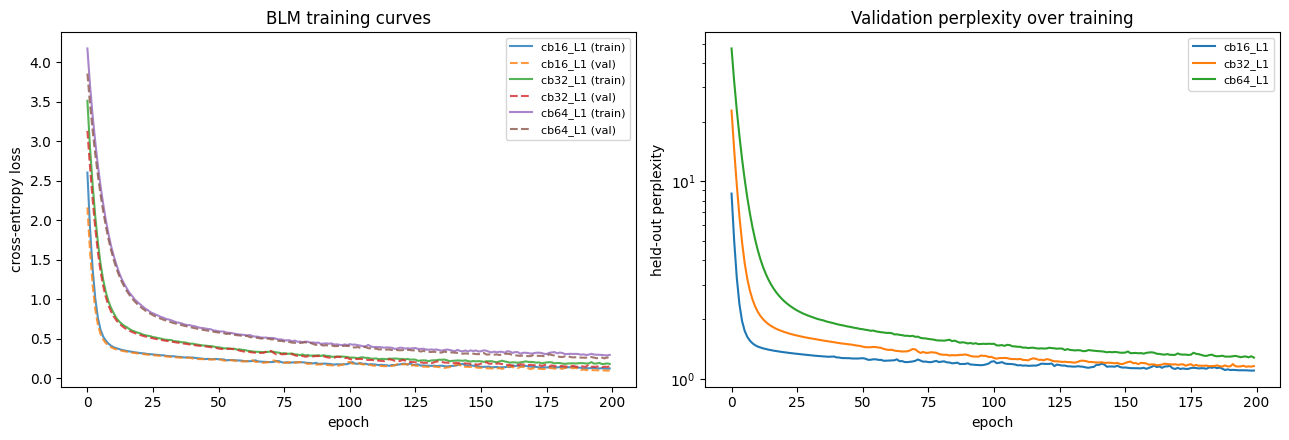

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, result in blm_results.items():
    axes[0].plot(result["history"]["train_loss"], label=f"{name} (train)", alpha=0.8)
    axes[0].plot(result["history"]["val_loss"], label=f"{name} (val)", linestyle="--", alpha=0.8)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].set_title("BLM training curves")
axes[0].legend(fontsize=8)

for name, result in blm_results.items():
    axes[1].plot(result["history"]["val_ppl"], label=name)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("held-out perplexity")
axes[1].set_title("Validation perplexity over training")
axes[1].legend(fontsize=8)
axes[1].set_yscale("log")

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "training_curves.png"), dpi=150)
plt.show()


## 6. Plot — headline comparison: held-out perplexity per config

This is the number that answers the original question: which tokenizer
actually produces the best language model. Lower perplexity = the model is
less "surprised" by the actual next token on held-out recordings, i.e. it
learned real predictive structure rather than memorizing.

A uniform-random baseline (perplexity = vocab size, since a model with no
information would spread probability evenly across all tokens) is included
for scale — the gap between a config's bar and its baseline line is the
actual signal being measured.


 config  vocab_size  best_val_loss  best_val_ppl  random_baseline_ppl
cb16_L1          16       0.094807      1.099447                   16
cb32_L1          32       0.140249      1.150561                   32
cb64_L1          64       0.246401      1.279412                   64


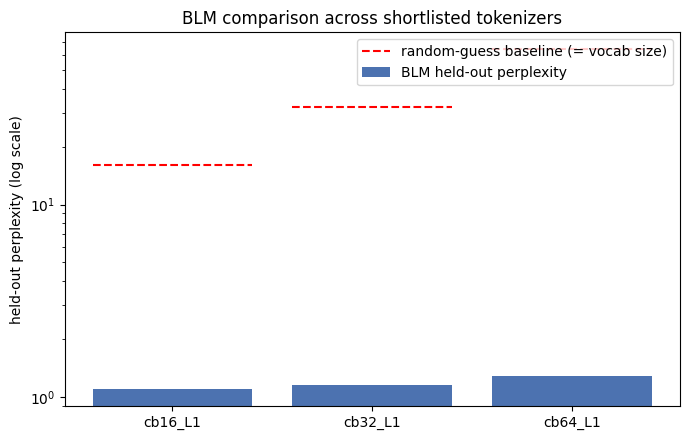

In [ ]:
comparison_rows = []
for name, result in blm_results.items():
    comparison_rows.append({
        "config": name,
        "vocab_size": result["vocab_size"],
        "best_val_loss": result["best_val_loss"],
        "best_val_ppl": result["best_val_ppl"],
        "random_baseline_ppl": result["vocab_size"],
    })
comparison_df = pd.DataFrame(comparison_rows).sort_values("best_val_ppl")
print(comparison_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(comparison_df))
bars = ax.bar(x, comparison_df["best_val_ppl"], color="#4C72B0", label="BLM held-out perplexity")
for xi, row in zip(x, comparison_df.itertuples()):
    ax.hlines(row.random_baseline_ppl, xi - 0.4, xi + 0.4, color="red", linestyle="--", linewidth=1.5)
ax.plot([], [], color="red", linestyle="--", label="random-guess baseline (= vocab size)")
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["config"])
ax.set_ylabel("held-out perplexity (log scale)")
ax.set_yscale("log")
ax.set_title("BLM comparison across shortlisted tokenizers")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "perplexity_comparison.png"), dpi=150)
plt.show()


## 7. Plot — next-token prediction diagnostics (best config)

Two more views into whether the winning BLM learned something real, using
the config with the lowest held-out perplexity:

- **Top-k accuracy**: how often the true next token is in the model's top-1 /
  top-3 / top-5 predictions — more interpretable than perplexity alone.
- **Confidence calibration**: when the model is, say, 70% confident, is it
  right about 70% of the time? A well-behaved model's calibration curve
  tracks the diagonal; a badly overfit or undertrained one will not.


In [ ]:
best_config_name = comparison_df.iloc[0]["config"]
best_model = blm_models[best_config_name]
best_result = blm_results[best_config_name]
print(f"Best config by held-out perplexity: {best_config_name}")

cfg_data = shortlist[best_config_name]
flat_labels = cfg_data["token_labels_flat"]
sequences = rebuild_sequences(flat_labels, sequence_lengths)
sequences_remapped, vocab_size, id_map = remap_vocab(sequences)
seq_val = [sequences_remapped[i] for i in val_rec_idx]
val_batches = make_batches(seq_val, BATCH_SIZE, best_result["pad_value"])

best_model.eval()
all_top1_correct, all_top3_correct, all_top5_correct = [], [], []
all_confidences, all_correct_at_argmax = [], []

with torch.no_grad():
    for batch_tokens, batch_mask in val_batches:
        batch_tokens_t = torch.tensor(batch_tokens, device=device)
        batch_mask_t = torch.tensor(batch_mask, device=device)
        inputs = batch_tokens_t[:, :-1]
        targets = batch_tokens_t[:, 1:]
        input_mask = batch_mask_t[:, :-1]
        valid = (targets != best_result["pad_value"])

        logits = best_model(inputs, padding_mask=input_mask)
        probs = F.softmax(logits, dim=-1)

        topk = torch.topk(logits, k=5, dim=-1).indices
        targets_exp = targets.unsqueeze(-1)
        correct_topk = (topk == targets_exp)

        for k, bucket in zip([1, 3, 5], [all_top1_correct, all_top3_correct, all_top5_correct]):
            hit = correct_topk[:, :, :k].any(dim=-1)
            bucket.append(hit[valid].cpu().numpy())

        max_probs, argmax_preds = probs.max(dim=-1)
        all_confidences.append(max_probs[valid].cpu().numpy())
        all_correct_at_argmax.append((argmax_preds == targets)[valid].cpu().numpy())

top1_acc = np.concatenate(all_top1_correct).mean()
top3_acc = np.concatenate(all_top3_correct).mean()
top5_acc = np.concatenate(all_top5_correct).mean()
confidences = np.concatenate(all_confidences)
correct_at_argmax = np.concatenate(all_correct_at_argmax)

print(f"Top-1 accuracy: {top1_acc:.1%} | Top-3: {top3_acc:.1%} | Top-5: {top5_acc:.1%}")
print(f"(Random-guess top-1 baseline: {1/vocab_size:.1%})")


Best config by held-out perplexity: cb16_L1
Top-1 accuracy: 97.2% | Top-3: 100.0% | Top-5: 100.0%
(Random-guess top-1 baseline: 6.2%)


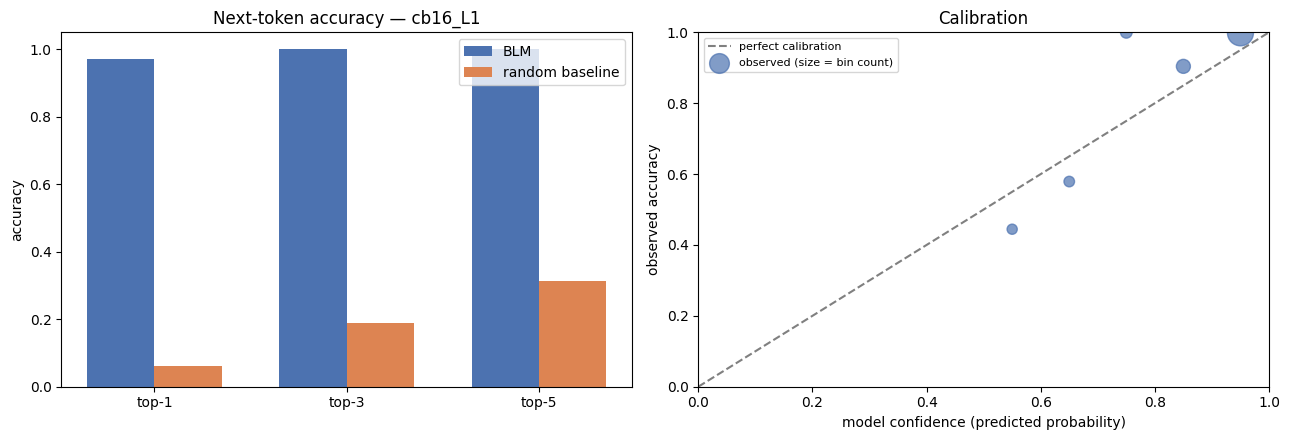

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Top-k accuracy bar chart
ks = [1, 3, 5]
accs = [top1_acc, top3_acc, top5_acc]
random_baselines = [min(k / vocab_size, 1.0) for k in ks]
x = np.arange(len(ks))
width = 0.35
axes[0].bar(x - width / 2, accs, width, label="BLM", color="#4C72B0")
axes[0].bar(x + width / 2, random_baselines, width, label="random baseline", color="#DD8452")
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"top-{k}" for k in ks])
axes[0].set_ylabel("accuracy")
axes[0].set_title(f"Next-token accuracy — {best_config_name}")
axes[0].legend()

# Calibration curve: bin by predicted confidence, plot observed accuracy per bin
n_bins = 10
bin_edges = np.linspace(0, 1, n_bins + 1)
bin_centers, observed_acc, bin_counts = [], [], []
for i in range(n_bins):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    mask = (confidences >= lo) & (confidences < hi) if i < n_bins - 1 else (confidences >= lo) & (confidences <= hi)
    if mask.sum() > 0:
        bin_centers.append((lo + hi) / 2)
        observed_acc.append(correct_at_argmax[mask].mean())
        bin_counts.append(mask.sum())

axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="perfect calibration")
sizes = np.array(bin_counts)
axes[1].scatter(bin_centers, observed_acc, s=50 + 300 * sizes / sizes.max() if len(sizes) else 50,
                 alpha=0.7, color="#4C72B0", label="observed (size = bin count)")
axes[1].set_xlabel("model confidence (predicted probability)")
axes[1].set_ylabel("observed accuracy")
axes[1].set_title("Calibration")
axes[1].legend(fontsize=8)
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "prediction_diagnostics.png"), dpi=150)
plt.show()


## 8. Save everything

Saves per-config BLM checkpoints (already done during training), the
comparison table, and prediction diagnostics — everything needed to write
this up without rerunning the notebook.


In [ ]:
summary = {
    "shortlist_names": shortlist_names,
    "comparison_table": comparison_df.to_dict(orient="records"),
    "best_config": best_config_name,
    "best_config_top1_acc": float(top1_acc),
    "best_config_top3_acc": float(top3_acc),
    "best_config_top5_acc": float(top5_acc),
    "train_rec_idx": train_rec_idx,
    "val_rec_idx": val_rec_idx,
}
with open(os.path.join(BLM_DIR, "blm_summary.pkl"), "wb") as f:
    pickle.dump(summary, f)

print("Saved BLM checkpoints to:", BLM_DIR)
print("Saved plots to:", PLOTS_DIR)
print("Saved summary to:", os.path.join(BLM_DIR, "blm_summary.pkl"))
print(f"\nBest tokenizer config for this mini dataset: {best_config_name} "
      f"(held-out perplexity {comparison_df.iloc[0]['best_val_ppl']:.3f}, "
      f"vs random baseline {comparison_df.iloc[0]['random_baseline_ppl']})")


Saved BLM checkpoints to: /content/drive/MyDrive/ds003844_processed/blm
Saved plots to: /content/drive/MyDrive/ds003844_processed/blm/plots
Saved summary to: /content/drive/MyDrive/ds003844_processed/blm/blm_summary.pkl

Best tokenizer config for this mini dataset: cb16_L1 (held-out perplexity 1.099, vs random baseline 16)


In [ ]:
cfg = shortlist[best_config_name]

flat_labels = cfg["token_labels_flat"]
sequences = rebuild_sequences(flat_labels, sequence_lengths)

rows = []

for rec_id, seq in enumerate(sequences):
    for window_id, token in enumerate(seq):
        rows.append({
            "recording_id": rec_id,
            "window_id": window_id,
            "token_id": int(token)
        })

token_sequence_df = pd.DataFrame(rows)

token_sequence_df.to_csv(
    os.path.join(BLM_DIR, "token_sequences.csv"),
    index=False
)

print(token_sequence_df.head())

   recording_id  window_id  token_id
0             0          0        13
1             0          1        13
2             0          2        13
3             0          3        13
4             0          4        13


In [ ]:
from collections import Counter

counts = Counter(flat_labels)

rows = []

for token in sorted(counts.keys()):
    rows.append({
        "token_id": int(token),
        "frequency": counts[token]
    })

token_vocab_df = pd.DataFrame(rows)

token_vocab_df.to_csv(
    os.path.join(BLM_DIR, "token_vocabulary.csv"),
    index=False
)

print(token_vocab_df.head())

   token_id  frequency
0         0        326
1         1         95
2         2        326
3         3        310
4         4        156
